In [1]:
import ee
import geopandas as gpd
import osmnx as ox
import folium
import requests
from PIL import Image
import numpy as np
from shapely.geometry import shape, mapping


C:\Users\akiran\AppData\Local\anaconda3\envs\project_geoAI\lib\site-packages\google\api_core\_python_version_support.py:275: FutureWarning: You are using a Python version (3.10.19) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


### 1. Get Google AlphaEarth Data

In [2]:
ee.Authenticate()

True

In [3]:
ee.Initialize(project='earthengine-project-487507')

<Axes: >

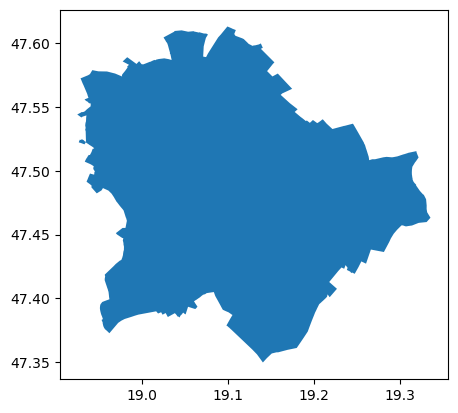

In [4]:
admin= ox.geocode_to_gdf ('Budapest')
geom= admin.iloc[0].geometry
admin.plot()

In [5]:
admin

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((18.92511 47.54414, 18.92979 47.54183...",18.925106,47.34969,19.334926,47.613147,60043387,relation,37244,47.48139,19.146094,boundary,administrative,12,0.808473,region,Budapest,"Budapest, Central Hungary, Hungary"


In [6]:
roi = ee.Geometry(mapping(geom))
print("ROI boundary:",roi.bounds().getInfo())

ROI boundary: {'geodesic': False, 'type': 'Polygon', 'coordinates': [[[18.9251057, 47.34968989999999], [19.334925799999997, 47.34968989999999], [19.334925799999997, 47.613146800000024], [18.9251057, 47.613146800000024], [18.9251057, 47.34968989999999]]]}


In [7]:
dataset= ee.ImageCollection ("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")

In [8]:
img_2024 = (
    dataset
        .filterDate("2024-01-01", "2025-01-01")
        .filterBounds(roi)
        .mean()
        .clip(roi)
)

In [9]:
print (img_2024. bandNames().getInfo())

['A00', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'A30', 'A31', 'A32', 'A33', 'A34', 'A35', 'A36', 'A37', 'A38', 'A39', 'A40', 'A41', 'A42', 'A43', 'A44', 'A45', 'A46', 'A47', 'A48', 'A49', 'A50', 'A51', 'A52', 'A53', 'A54', 'A55', 'A56', 'A57', 'A58', 'A59', 'A60', 'A61', 'A62', 'A63']


In [10]:
print (img_2024.getInfo())

{'type': 'Image', 'bands': [{'id': 'A00', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [2, 3], 'origin': [18, 46], 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}, {'id': 'A01', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [2, 3], 'origin': [18, 46], 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}, {'id': 'A02', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [2, 3], 'origin': [18, 46], 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}, {'id': 'A03', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [2, 3], 'origin': [18, 46], 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}, {'id': 'A04', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [2, 3], 'origin': [18, 46], 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}, {'id': 'A05', 'data_type': {'type': 'PixelType', 'precision': 'double'}, 'dimensions': [2, 3], 'origin': [1

In [11]:
vis_params = {"bands": ["A00", "A16", "A09"], "min": -0.3, "max": 0.3}

thumb_params = {"region": roi,
                "dimensions": 2048,
                "crs": "EPSG: 23700",
                "format": "png", **vis_params}

url = img_2024.getThumbURL (thumb_params)
print("Thumbnail URL:", url)

response = requests.get(url, stream=True) 
im = Image.open (response.raw).convert("RGB")
arr = np.array(im)
arr

Thumbnail URL: https://earthengine.googleapis.com/v1/projects/earthengine-project-487507/thumbnails/fd1b92a86276d85d58b00463032f25db-63b49093fb906a3c38d4293ef4432c7a:getPixels


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(1943, 2048, 3), dtype=uint8)

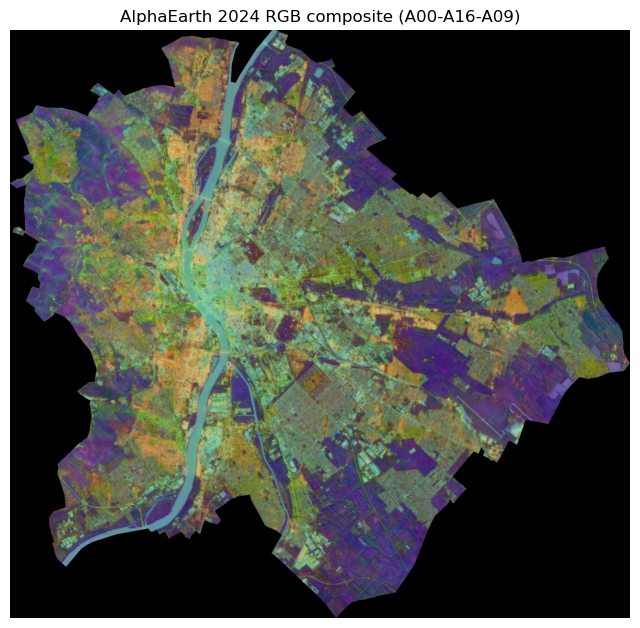

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.imshow(arr)
plt.title("AlphaEarth 2024 RGB composite (A00-A16-A09)")
plt.axis("off")
plt.show()

### 2. Get buildings from OSM

<Axes: >

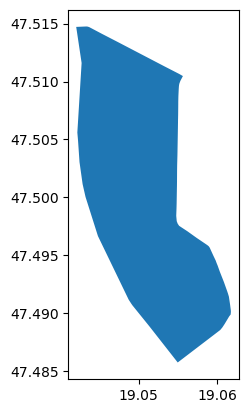

In [13]:
admin = ox.geocode_to_gdf ('5th District, Budapest')
geom = admin.iloc[0].geometry
admin.plot()

Number of buildings: 1076


geometry access  \
element  id                                                                     
node     263960784                           POINT (19.05099 47.50945)    yes   
         6430287665                          POINT (19.04929 47.49312)    NaN   
relation 11764       POLYGON ((19.04748 47.51245, 19.04724 47.51173...    NaN   
         11766       POLYGON ((19.0481 47.50746, 19.04812 47.50746,...    NaN   
         11768       POLYGON ((19.04557 47.50473, 19.04596 47.50477...    NaN   
...                                                                ...    ...   
way      1419728554  POLYGON ((19.05084 47.50111, 19.05085 47.50109...    NaN   
         1449389751  POLYGON ((19.05107 47.49962, 19.05108 47.49959...    NaN   
         1464425588  POLYGON ((19.04734 47.5096, 19.04734 47.50959,...    NaN   
         1465736842  POLYGON ((19.05546 47.49688, 19.05541 47.49683...    NaN   
         1474860348  POLYGON ((19.0527 47.50953, 19.0528 47.50984, ...    NaN   

                     amenity    building   charge drinking_water  fee  \
element  id                                                             
node     263960784   toilets     toilets  250 HUF             no  yes   
         6430287665      bar        ship      NaN            NaN  NaN   
relation 11764           NaN       civic      NaN            NaN  NaN   
         11766           NaN         yes      NaN            NaN  NaN   
         11768           NaN  apartments      NaN            NaN  NaN   
...                      ...         ...      ...            ...  ...   
way      1419728554      NaN         yes      NaN            NaN  NaN   
         1449389751      NaN        roof      NaN            NaN  NaN   
         1464425588      NaN  industrial      NaN            NaN  NaN   
         1465736842      NaN  commercial      NaN            NaN  NaN   
         1474860348      NaN         yes      NaN            NaN  NaN   

                    handwashing:creme handwashing:hand_cleaning_paste  \
element  id                                                             
node     263960784                 no                              no   
         6430287665               NaN                             NaN   
relation 11764                    NaN                             NaN   
         11766                    NaN                             NaN   
         11768                    NaN                             NaN   
...                               ...                             ...   
way      1419728554               NaN                             NaN   
         1449389751               NaN                             NaN   
         1464425588               NaN                             NaN   
         1465736842               NaN                             NaN   
         1474860348               NaN                             NaN   

                    handwashing:hand_disinfection  ... roof:colour fixme  \
element  id                                        ...                     
node     263960784                             no  ...         NaN   NaN   
         6430287665                           NaN  ...         NaN   NaN   
relation 11764                                NaN  ...         NaN   NaN   
         11766                                NaN  ...         NaN   NaN   
         11768                                NaN  ...         NaN   NaN   
...                                           ...  ...         ...   ...   
way      1419728554                           NaN  ...         NaN   NaN   
         1449389751                           NaN  ...         NaN   NaN   
         1464425588                           NaN  ...         NaN   NaN   
         1465736842                           NaN  ...         NaN   NaN   
         1474860348                           NaN  ...         NaN   NaN   

                    name:el name:fi name:tr sauna castle_type building:flats  \
element  id                            

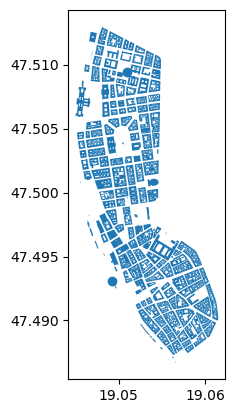

In [14]:
buildings =  ox.features_from_polygon(geom, tags={'building': True})
buildings.plot()
print("Number of buildings:", len (buildings))
buildings

In [15]:
buildings = ox.features_from_polygon(geom, tags={'building': True})

# Bring index (element + id) into columns
buildings = buildings.reset_index()

# Keep only polygons
buildings = buildings[buildings.geometry.type.isin(['Polygon', 'MultiPolygon'])].copy()

# Rename id to osmid if you want
buildings['osmid'] = buildings['id']

# Keep only important columns
buildings = buildings[['osmid', 'building', 'amenity', 'geometry']]

# Clean
buildings = buildings.drop_duplicates(subset='osmid').dropna(subset=['geometry']).reset_index(drop=True)

print("Cleaned buildings:", len(buildings))


Cleaned buildings: 1074


### 3.Map AlphaEarth features into footprints

In [16]:
results = []

for start in range(0, len(buildings), 100):

    subset = buildings.iloc[start:start+100]

    fc = ee.FeatureCollection([
        ee.Feature(
            ee.Geometry(mapping(geom)),
            {'osmid': int(osmid)}
        )
        for osmid, geom in zip(subset['osmid'], subset.geometry)
    ])

    stats = (
        img_2024
        .select([f"A{str(b).zfill(2)}" for b in range(64)])
        .reduceRegions(
            collection=fc,
            reducer=ee.Reducer.mean(),
            scale=10
        )
        .getInfo()
    )

    for f in stats.get('features', []):
        props = f.get('properties', {}) or {}
        geom = f.get('geometry')

        if geom:
            props['geometry'] = shape(geom)

        results.append(props)

# Optional preview
results[:10]


[{'A00': 0.1314656051443713,
  'A01': -0.19180857091638737,
  'A02': -0.009256528982721248,
  'A03': -0.20239332851836284,
  'A04': 0.0633353795997042,
  'A05': -0.07222799211697493,
  'A06': 0.21047678774991607,
  'A07': -0.022255254533440703,
  'A08': -0.10281071305946415,
  'A09': 0.0012355337133432558,
  'A10': 0.005195318526818867,
  'A11': -0.129820357026408,
  'A12': -0.08647855618519078,
  'A13': -0.11380600357260817,
  'A14': -0.15715371456909,
  'A15': -0.23244814347920245,
  'A16': 0.14825420430884137,
  'A17': 0.046818213346229605,
  'A18': -0.0034338309507299463,
  'A19': 0.1473448204771125,
  'A20': 0.0866847545085589,
  'A21': 0.014749084511953949,
  'A22': -0.23634192899705478,
  'A23': -0.008188900551646526,
  'A24': 0.12616487988224273,
  'A25': 0.13904022229561888,
  'A26': 0.09741961007193446,
  'A27': -0.04794337932917432,
  'A28': 0.11256253841552895,
  'A29': -0.055845983198327794,
  'A30': 0.06976175887450356,
  'A31': -0.08790725360118863,
  'A32': -0.036790178

In [17]:
buildings_alphaearth = gpd.GeoDataFrame(results, crs="EPSG:4326") 
len(buildings_alphaearth)

1074

In [18]:
buildings_alphaearth.head()

,A00,A01,A02,A03,A04,A05,A06,A07,A08,A09,...,A56,A57,A58,A59,A60,A61,A62,A63,osmid,geometry
0,0.131466,-0.191809,-0.009257,-0.202393,0.063335,-0.072228,0.210477,-0.022255,-0.102811,0.001236,...,0.079877,0.072254,0.016116,-0.016954,0.162573,-0.082672,-0.242892,0.179093,11764,"POLYGON ((19.04748 47.51245, 19.04724 47.51173..."
1,0.055992,-0.244340,0.056531,-0.173767,0.092499,-0.178592,0.038528,-0.043606,-0.153225,0.027182,...,0.111391,0.032891,0.068512,-0.052995,0.115507,-0.053112,-0.187631,0.044834,11766,"POLYGON ((19.0481 47.50746, 19.04812 47.50746,..."
2,0.002179,-0.263705,0.072805,-0.172273,0.045071,-0.195659,0.013854,-0.006894,-0.110129,-0.003192,...,0.060527,-0.005022,0.086902,-0.070370,0.064285,-0.063148,-0.065274,0.017975,11768,"POLYGON ((19.04557 47.50473, 19.04596 47.50477..."
3,0.002463,-0.219833,0.149158,-0.161957,0.071851,-0.184497,-0.000696,-0.053560,-0.129900,-0.036102,...,0.060857,-0.060855,0.086467,-0.079150,0.071020,-0.008412,-0.075048,-0.053122,11772,"POLYGON ((19.04612 47.50149, 19.04623 47.5015,..."
4,0.002248,-0.251861,0.109751,-0.117809,0.066689,-0.161661,-0.003070,-0.062339,-0.125180,0.006667,...,0.070324,-0.032346,0.104165,-0.065788,0.075273,-0.047665,-0.073296,-0.079213,11832,"POLYGON ((19.04942 47.50439, 19.04953 47.50389..."


In [19]:
import folium
import numpy as np
import matplotlib.colors as mcolors
import random

# Keep only polygons
buildings_alphaearth = buildings_alphaearth[
    buildings_alphaearth.geometry.type == "Polygon"
].copy()

# Create map centered at buildings centroid
m = folium.Map(
    location=[
        buildings_alphaearth.geometry.centroid.y.mean(),
        buildings_alphaearth.geometry.centroid.x.mean()
    ],
    zoom_start=14,
    tiles="cartodbpositron"
)

# Generate band names A00–A63
bands = [f"A{str(i).zfill(2)}" for i in range(64)]

for band in bands:

    if band not in buildings_alphaearth.columns:
        continue

    # Define min/max for normalization
    vmin = buildings_alphaearth[band].min()
    vmax = buildings_alphaearth[band].max()

    # Create random colormap
    cmap = mcolors.LinearSegmentedColormap.from_list(
        "trippy",
        [random.choice(list(mcolors.CSS4_COLORS.values())) for _ in range(5)]
    )

    # Style function
    def style_fn(feature, band=band, cmap=cmap, vmin=vmin, vmax=vmax):

        val = feature["properties"].get(band)

        if val is None or np.isnan(val):
            color = "#000000"
        else:
            norm_val = (val - vmin) / (vmax - vmin) if vmax != vmin else 0
            rgba = cmap(norm_val)
            color = mcolors.rgb2hex(rgba)

        return {
            "fillColor": color,
            "color": color,
            "weight": 0.1,
            "fillOpacity": 0.7
        }

    # Convert to GeoJSON
    gjson = buildings_alphaearth[[band, "geometry"]].to_json()

    folium.GeoJson(
        gjson,
        name=f"{band}",
        style_function=style_fn,
        tooltip=folium.GeoJsonTooltip(fields=[band])
    ).add_to(m)

# Add layer control
folium.LayerControl(collapsed=False).add_to(m)

m

C:\Users\akiran\AppData\Local\Temp\ipykernel_23632\2939518633.py:14: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  buildings_alphaearth.geometry.centroid.y.mean(),
C:\Users\akiran\AppData\Local\Temp\ipykernel_23632\2939518633.py:15: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  buildings_alphaearth.geometry.centroid.x.mean()


### 4.Building Type Prediction

In [20]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score 
from sklearn.metrics import classification_report, confusion_matrix 
import matplotlib.pyplot as plt
from collections import Counter

In [21]:
buildings[['osmid', 'amenity', 'building']]

,osmid,amenity,building
0,11764,NaN,civic
1,11766,NaN,yes
2,11768,NaN,apartments
3,11772,NaN,yes
4,11832,NaN,public
...,...,...,...
1069,1419728554,NaN,yes
1070,1449389751,NaN,roof
1071,1464425588,NaN,industrial
1072,1465736842,NaN,commercial


In [22]:
Counter(buildings.dropna(subset = ['building']).building).most_common()

[('apartments', 648),
 ('yes', 184),
 ('office', 47),
 ('public', 33),
 ('hotel', 31),
 ('commercial', 27),
 ('school', 16),
 ('university', 16),
 ('government', 11),
 ('church', 11),
 ('roof', 9),
 ('construction', 7),
 ('residential', 5),
 ('abandoned', 4),
 ('transportation', 4),
 ('retail', 4),
 ('ship', 3),
 ('kiosk', 2),
 ('service', 2),
 ('civic', 1),
 ('bank', 1),
 ('kindergarten', 1),
 ('parking', 1),
 ('house', 1),
 ('fire_station', 1),
 ('basilica', 1),
 ('sports_centre', 1),
 ('toilets', 1),
 ('industrial', 1)]

In [23]:
df = buildings_alphaearth.copy()
df = df.merge (buildings, left_on = 'osmid', right_on = 'osmid')
df= df[df["building"].isin(["office", "university"])].reset_index(drop=True) 
df = df.drop(columns =['geometry_x', 'geometry_y'])
df

,A00,A01,A02,A03,A04,A05,A06,A07,A08,A09,...,A57,A58,A59,A60,A61,A62,A63,osmid,building,amenity
0,0.036615,-0.168417,0.198152,-0.152615,0.070866,-0.121790,0.086200,-0.028385,-0.175069,-0.033215,...,-0.057053,0.160246,-0.067047,0.057059,-0.045986,-0.073705,-0.060705,11844,office,bank
1,-0.001286,-0.179930,0.168581,-0.136781,0.078095,-0.166685,0.028823,-0.042784,-0.121355,-0.055772,...,-0.098129,0.105042,-0.113245,0.050859,0.022770,-0.061801,-0.065585,11891,office,NaN
2,0.017731,-0.221181,0.109562,-0.146007,0.064609,-0.202121,-0.016198,-0.070604,-0.091572,-0.033468,...,-0.079219,0.076962,-0.130753,0.058624,0.014130,-0.055659,-0.033719,11898,office,NaN
3,-0.012068,-0.204854,0.141657,-0.172623,0.075874,-0.163160,0.006142,-0.046019,-0.099797,-0.023540,...,-0.078701,0.133316,-0.111241,0.063074,0.010370,-0.015324,-0.089947,11914,office,NaN
4,0.070668,-0.176908,0.114205,-0.180411,0.085670,-0.119051,0.099349,-0.115225,-0.115656,-0.048846,...,-0.041500,0.081095,-0.115778,0.081975,-0.000475,-0.184409,0.025239,11917,office,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,0.049011,-0.161830,0.052834,-0.110763,0.118274,-0.129684,0.118116,0.052562,-0.234689,0.066547,...,-0.025928,0.103945,-0.152622,0.109402,-0.005872,-0.065781,0.012732,519696082,office,NaN
59,0.008650,-0.196294,0.117338,-0.155186,0.081909,-0.177227,0.022052,-0.066645,-0.115327,0.001418,...,-0.080370,0.114098,-0.167673,0.072881,0.029497,-0.039415,-0.057741,678699924,university,NaN
60,0.009667,-0.210790,0.136990,-0.179532,0.078225,-0.139364,0.019194,-0.017635,-0.135373,0.023223,...,-0.024365,0.132887,-0.118112,0.064397,-0.009925,-0.070372,-0.100888,759145545,university,NaN
61,0.012099,-0.203136,0.101288,-0.094057,0.070381,-0.205080,0.030339,-0.043812,-0.077958,-0.051824,...,-0.064775,0.073211,-0.115462,0.075861,-0.011297,-0.042615,-0.001366,1214344425,office,NaN


In [24]:
features= [f"A{str(i).zfill(2)}" for i in range(64)]
X = df[features].values
y = (df["building"] == "office").astype (int) # office=1, university=0
len (df), len(features)

(63, 64)

In [25]:
scaler = StandardScaler() 
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=10)
X_pca= pca.fit_transform(X_scaled)
print(f"Explained variance: {pca.explained_variance_ratio_.sum():.2%}")

Explained variance: 94.15%


In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA().fit(X_scaled)

explained_var= np.cumsum(pca. explained_variance_ratio_)*100
explained_var

array([ 32.33455181,  53.73506072,  66.21577333,  74.69741627,
        80.76667564,  84.66715563,  88.39155488,  91.12671732,
        92.95448886,  94.15174516,  95.08085884,  95.94598194,
        96.59056037,  97.12492577,  97.51084576,  97.85084934,
        98.16029651,  98.41456595,  98.64866527,  98.81846924,
        98.97177338,  99.10062786,  99.21022498,  99.30331054,
        99.39095526,  99.46169813,  99.52819512,  99.59055679,
        99.64358799,  99.68697299,  99.72618263,  99.76005919,
        99.78833055,  99.81464706,  99.83789709,  99.8592997 ,
        99.87839748,  99.89485751,  99.90928968,  99.92198585,
        99.93336415,  99.94402721,  99.95336193,  99.96179882,
        99.96889608,  99.97572565,  99.98080339,  99.98495136,
        99.98866355,  99.99147617,  99.99354949,  99.99519945,
        99.99666343,  99.99764487,  99.99833989,  99.99887899,
        99.99937063,  99.99964711,  99.99983599,  99.99996172,
        99.9999987 , 100.        , 100.        ])

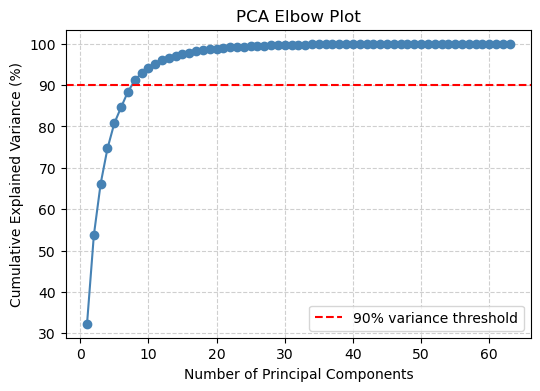

In [27]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len (explained_var) + 1), explained_var, marker='o', color='steelblue')
plt.axhline(90, color='red', linestyle='--', label='90% variance threshold')


plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('PCA Elbow Plot')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay 
import matplotlib.pyplot as plt

In [29]:
ros = RandomOverSampler (sampling_strategy='auto', random_state=42)
X_bal, y_bal = ros.fit_resample(X_pca, y)

X_train, X_test, y_train, y_test = train_test_split(X_bal, y_bal, test_size=0.3, random_state=42, stratify=y_bal)

clf = SVC(kernel="rbf", C=1, gamma="scale", random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.87      0.84        15
           1       0.85      0.79      0.81        14

    accuracy                           0.83        29
   macro avg       0.83      0.83      0.83        29
weighted avg       0.83      0.83      0.83        29



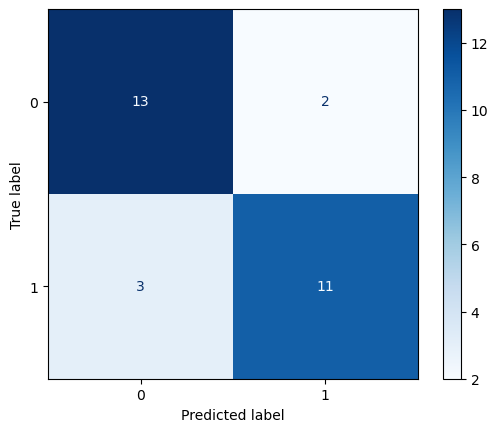

In [30]:
cm = confusion_matrix (y_test, y_pred)
ConfusionMatrixDisplay(cm,display_labels=clf.classes_).plot(cmap="Blues")